# Session 4: Variance, Covariance, Joint Distributions

*ECE 225A, Module 01 (Probability Review), slides 55-69*

Session 3 summarized a random variable by one number, its mean. This session adds a second summary, the **variance**, which measures how far the variable typically lands from its mean, together with its square root, the **standard deviation**. It then moves from one random variable to two. A **joint distribution** describes a pair, the **covariance** measures whether the two tend to move together, and the **correlation coefficient** rescales the covariance into a unit-free number between $-1$ and $1$. Two facts come up again and again: independence implies zero covariance (but not the other way around), and the variances of independent variables add.

## Learning objectives

After this session you should be able to:

1. Compute a variance both from the definition $E[(X - \mu)^2]$ and from the shortcut $E[X^2] - \mu^2$, and take its square root to get the standard deviation.
2. Derive the Bernoulli variance $p(1 - p)$ and explain why it is largest at $p = 1/2$.
3. Find the mean, variance, and standard deviation of $aX + b$ without working out its distribution.
4. Read a joint PMF from a table or from a uniform distribution over a support, and find its marginals.
5. Compute a covariance two ways and use its properties (symmetry, shift invariance, bilinearity).
6. Explain why independence implies zero covariance, and build a pair of variables that are uncorrelated but dependent.
7. Find $V(X + Y)$ from the two variances and the covariance.
8. Compute a correlation coefficient, use its invariance to units, and prove that $\lvert\rho\rvert \le 1$.

## Prerequisites

- Expectation, LOTUS $E[g(X)] = \sum_x g(x)\,p(x)$, and linearity of expectation (Session 3).
- The PMF and CDF of a discrete random variable, and the Bernoulli distribution $B_p$ (Session 3).
- Independence of events, $P(A \cap B) = P(A)\,P(B)$ (Session 2), and the law of total probability (Session 3).

In [1]:
from fractions import Fraction
from itertools import product
from math import sqrt

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

rng = np.random.default_rng(225)

BLUE, ORANGE, INK, MUTED, FAINT, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def show(label, v):
    # Print an exact value as a fraction and as a decimal.
    print(f"{label}: {v} = {float(v):.6f}")


def E(pmf, g=lambda w: w):
    # LOTUS: E[g] = sum of g(w) p(w) over the outcomes w listed in the PMF.
    return sum((g(w) * p for w, p in pmf.items()), Fraction(0))

## 1. Variance and standard deviation (slides 55-56)

**Intuition.** The mean says where a distribution balances, but not how far its values typically fall from that point. A fair die, a die with faces 3, 3, 3, 4, 4, 4, and a die with faces 1, 1, 1, 6, 6, 6 all have mean 3.5, yet they spread out very differently.

To measure spread, look at the deviation $X - \mu$ from the mean. Its average is useless: positive and negative deviations cancel exactly, since $E[X - \mu] = E[X] - \mu = 0$ for every $X$. Squaring removes the sign, and it also penalizes large deviations more than small ones.

**Formal definitions.** Let $\mu = E[X]$. The **variance** of $X$ is the expected squared deviation from the mean,

$$V(X) = E\big[(X - \mu)^2\big] = \sum_x (x - \mu)^2\, p(x),$$

also written $V[X]$, $\mathrm{Var}(X)$, $\sigma_X^2$, or just $V$. (The sum is LOTUS with $g(x) = (x - \mu)^2$.) The **standard deviation** (std) is the nonnegative square root,

$$\sigma_X = +\sqrt{V(X)}.$$

The variance is in squared units (dollars squared, if $X$ is in dollars). The std is back in the units of $X$, so it reads as a typical distance from the mean.

Like the mean, both are **constants**, not random, and both are **functionals of the distribution**: they depend only on the PMF of $X$, not on the experiment that produced it.

**Equivalent formula.** Expand the square and apply linearity, remembering that $\mu$ is a constant:

$$V(X) = E\big[X^2 - 2\mu X + \mu^2\big] = E[X^2] - 2\mu\,E[X] + \mu^2 = E[X^2] - \mu^2.$$

In words: the mean of the square minus the square of the mean. Since $V(X) \ge 0$, this also proves $E[X^2] \ge (E[X])^2$. Equality holds only when $V(X) = 0$, and because $V(X) = \sum_x (x - \mu)^2 p(x)$ is a sum of nonnegative terms, that forces $p(x) = 0$ for every $x \ne \mu$: a variable with zero variance is a constant (with probability 1).

**Example: a fair die.** These slides give no numerical example, so take a fair die, with $\mu = 7/2$.

| $x$ | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| $x - \mu$ | $-5/2$ | $-3/2$ | $-1/2$ | $1/2$ | $3/2$ | $5/2$ |
| $(x - \mu)^2$ | $25/4$ | $9/4$ | $1/4$ | $1/4$ | $9/4$ | $25/4$ |

1. Definition: every value has probability $1/6$, so $V(X) = \frac{1}{6} \cdot \frac{25 + 9 + 1 + 1 + 9 + 25}{4} = \frac{70}{24} = \frac{35}{12} \approx 2.917$.
2. Shortcut: $E[X^2] = \frac{1 + 4 + 9 + 16 + 25 + 36}{6} = \frac{91}{6}$, so $V(X) = \frac{91}{6} - \frac{49}{4} = \frac{182 - 147}{12} = \frac{35}{12}$.
3. Std: $\sigma_X = \sqrt{35/12} \approx 1.708$. A roll typically lands about 1.7 pips from 3.5.

In [2]:
def Var(pmf, g=lambda w: w):
    # V = E[(g - mu)^2], straight from the definition.
    mu = E(pmf, g)
    return E(pmf, lambda w: (g(w) - mu) ** 2)


die = {x: Fraction(1, 6) for x in range(1, 7)}
mu = E(die)
show("E[X]                ", mu)
show("V(X), definition    ", Var(die))
show("V(X), E[X^2] - mu^2 ", E(die, lambda x: x * x) - mu ** 2)
print(f"std sigma_X: {sqrt(Var(die)):.6f}")

E[X]                : 7/2 = 3.500000
V(X), definition    : 35/12 = 2.916667
V(X), E[X^2] - mu^2 : 35/12 = 2.916667
std sigma_X: 1.707825


**Monte Carlo check.** Roll a million dice and compare the sample variance and sample std with the exact values.

In [3]:
rolls = rng.integers(1, 7, size=1_000_000)
print(f"V(X): simulated {rolls.var():.4f}   exact {float(Var(die)):.4f}")
print(f"std : simulated {rolls.std():.4f}   exact {sqrt(Var(die)):.4f}")

V(X): simulated 2.9189   exact 2.9167
std : simulated 1.7085   exact 1.7078


The three dice below all have mean 3.5 (dashed line). The shaded band covers $\mu \pm \sigma$. As the mass moves away from the mean, the variance grows from $1/4$ to $25/4$, and the band widens with it.

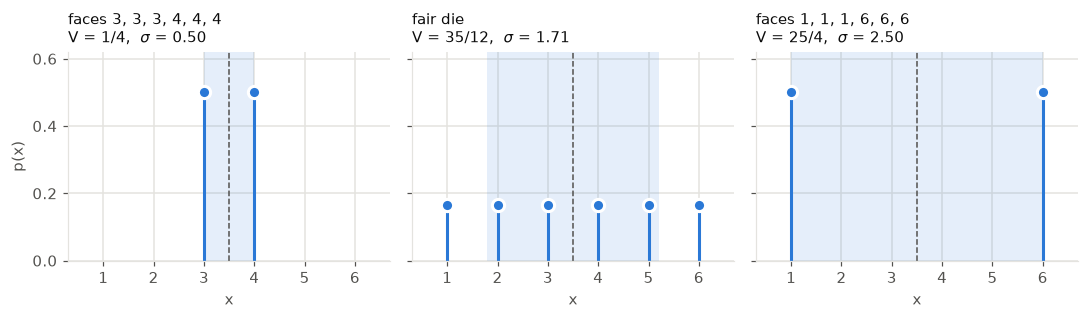

In [4]:
same_mean = {
    "faces 3, 3, 3, 4, 4, 4": {3: Fraction(1, 2), 4: Fraction(1, 2)},
    "fair die": die,
    "faces 1, 1, 1, 6, 6, 6": {1: Fraction(1, 2), 6: Fraction(1, 2)},
}
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, (name, pmf) in zip(axes, same_mean.items()):
    m, sd = float(E(pmf)), sqrt(Var(pmf))
    ax.axvspan(m - sd, m + sd, color=BLUE, alpha=0.12, lw=0)
    ax.axvline(m, color=MUTED, lw=1, ls="--")
    xs, ps = list(pmf), [float(p) for p in pmf.values()]
    ax.vlines(xs, 0, ps, color=BLUE, lw=2)
    ax.plot(xs, ps, "o", color=BLUE, ms=8, mec="white", mew=2)
    ax.set(xlim=(0.3, 6.7), ylim=(0, 0.62), xticks=range(1, 7), xlabel="x")
    ax.set_title(f"{name}\nV = {Var(pmf)},  $\\sigma$ = {sd:.2f}", color=INK, loc="left", fontsize=10)
axes[0].set_ylabel("p(x)")
plt.tight_layout()
plt.show()

## 2. Bernoulli variance (slide 57)

**Setup.** $X \sim B_p$ equals 1 with probability $p$ and 0 with probability $q = 1 - p$, and its mean is $\mu = p$ (Session 3).

**Route 1: the definition.** List each value with its deviation from the mean and the squared deviation.

| $x$ | $p(x)$ | $x - \mu$ | $(x - \mu)^2$ |
|---|---|---|---|
| 0 | $q$ | $0 - p = -p$ | $p^2$ |
| 1 | $p$ | $1 - p = q$ | $q^2$ |

The value 0 sits a distance $p$ below the mean, and the value 1 sits a distance $q$ above it. Weighting the squared distances by their probabilities,

$$V(X) = q \cdot p^2 + p \cdot q^2 = pq\,(p + q) = pq.$$

**Route 2: the shortcut.** Since $0^2 = 0$ and $1^2 = 1$, we have $X^2 = X$, so $E[X^2] = (1 - p) \cdot 0^2 + p \cdot 1^2 = p$ and

$$V(X) = E[X^2] - (E[X])^2 = p - p^2 = p(1 - p) = pq.$$

Both routes give $V(X) = pq$ and $\sigma_X = \sqrt{pq}$.

**Example: $B_{0.75}$.** Here $\mu = 0.75$. The value 0 is $0.75$ below the mean (probability $0.25$) and the value 1 is $0.25$ above it (probability $0.75$), so

$$V = 0.25 \cdot 0.75^2 + 0.75 \cdot 0.25^2 = 0.140625 + 0.046875 = 0.1875 = \tfrac{3}{16}, \qquad \sigma = \tfrac{\sqrt{3}}{4} \approx 0.433.$$

The rare value 0 is far from the mean, and the common value 1 is close to it.

In [5]:
def bernoulli(p):
    return {0: 1 - p, 1: p}


p = Fraction(3, 4)
q = 1 - p
show("definition  q p^2 + p q^2", q * p ** 2 + p * q ** 2)
show("shortcut    p - p^2      ", p - p ** 2)
show("helper      Var(B_0.75)  ", Var(bernoulli(p)))
print(f"std sqrt(pq) = {sqrt(p * q):.6f}")
assert all(Var(bernoulli(Fraction(k, 20))) == Fraction(k, 20) * (1 - Fraction(k, 20)) for k in range(21))

samples = (rng.random(1_000_000) < 0.75).astype(int)
print(f"B_0.75 variance: simulated {samples.var():.4f}   exact {float(p * q):.4f}")

definition  q p^2 + p q^2: 3/16 = 0.187500
shortcut    p - p^2      : 3/16 = 0.187500
helper      Var(B_0.75)  : 3/16 = 0.187500
std sqrt(pq) = 0.433013
B_0.75 variance: simulated 0.1872   exact 0.1875


How does the variance depend on $p$? Completing the square, $pq = p(1 - p) = \frac{1}{4} - \left(p - \frac{1}{2}\right)^2$, a downward parabola. It is 0 at $p = 0$ and $p = 1$, where $X$ is a constant, and largest, $1/4$, at $p = 1/2$, the least predictable coin. Swapping $p$ and $q$ does not change $pq$, so $B_{0.25}$ and $B_{0.75}$ have the same variance.

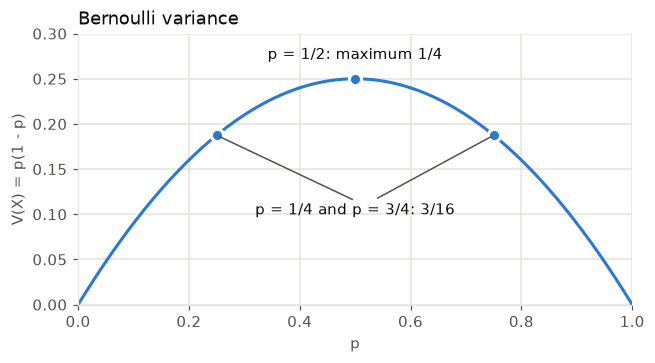

In [6]:
grid_p = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(grid_p, grid_p * (1 - grid_p), color=BLUE, lw=2)
for p0 in (0.25, 0.5, 0.75):
    ax.plot([p0], [p0 * (1 - p0)], "o", color=BLUE, ms=8, mec="white", mew=2)
ax.annotate("p = 1/2: maximum 1/4", xy=(0.5, 0.25), xytext=(0.5, 0.272), ha="center", color=INK)
ax.annotate("p = 1/4 and p = 3/4: 3/16", xy=(0.75, 0.1875), xytext=(0.5, 0.1), ha="center", color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.annotate("", xy=(0.25, 0.1875), xytext=(0.5, 0.115), arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.set(xlim=(0, 1), ylim=(0, 0.3), xlabel="p", ylabel="V(X) = p(1 - p)")
ax.set_title("Bernoulli variance", color=INK, loc="left")
plt.show()

## 3. Affine transformations (slide 58)

**Intuition.** Adding a constant $b$ slides the whole distribution along the line. The mean moves by $b$, but every distance to the mean stays the same, so the spread does not change. Multiplying by $a$ stretches every distance to the mean by the factor $\lvert a \rvert$, so squared distances grow by $a^2$. A negative $a$ also mirrors the distribution, which does not change any distance.

**Formal statement.** For constants $a$ and $b$,

$$V(aX + b) = V(aX) = a^2\, V(X), \qquad \sigma_{aX + b} = \lvert a \rvert\, \sigma_X.$$

**Proof.** By linearity, $E[aX + b] = a\mu + b$, so the deviation of $aX + b$ from its own mean is $(aX + b) - (a\mu + b) = a(X - \mu)$, and $b$ cancels. Then

$$V(aX + b) = E\big[a^2 (X - \mu)^2\big] = a^2\, E\big[(X - \mu)^2\big] = a^2\, V(X).$$

Taking the nonnegative square root, $\sigma_{aX + b} = \sqrt{a^2}\,\sigma_X = \lvert a \rvert\,\sigma_X$.

| Operation | New variable | Mean | Variance | Std |
|---|---|---|---|---|
| Translation (add $b$) | $X + b$ | $E[X] + b$ | $V(X)$ | $\sigma_X$ |
| Scaling (multiply by $a$) | $aX$ | $a\,E[X]$ | $a^2\, V(X)$ | $\lvert a \rvert\, \sigma_X$ |
| Affine (both) | $aX + b$ | $a\,E[X] + b$ | $a^2\, V(X)$ | $\lvert a \rvert\, \sigma_X$ |

**Example.** A die game pays 4 dollars per pip and costs 15 dollars to play, so your net gain is $G = 4X - 15$. Without finding the PMF of $G$:

- $E[G] = 4 \cdot \frac{7}{2} - 15 = -1$ dollar;
- $V(G) = 4^2 \cdot \frac{35}{12} = \frac{140}{3} \approx 46.67$ dollars squared;
- $\sigma_G = 4 \cdot 1.708 \approx 6.83$ dollars.

The casino's gain is $-G = 15 - 4X$. Its mean is $+1$, but its variance and std equal yours, since $(-4)^2 = 16$ and $\lvert -4 \rvert = 4$.

In [7]:
G = lambda x: 4 * x - 15
show("E[G]          ", E(die, G))
show("V(G), direct  ", Var(die, G))
show("16 V(X)       ", 16 * Var(die))
show("V(-G), casino ", Var(die, lambda x: 15 - 4 * x))
print(f"std of G: {sqrt(Var(die, G)):.4f} = 4 * {sqrt(Var(die)):.4f}")

for a, b in [(1, 10), (3, 0), (-2, 5), (Fraction(1, 2), -7)]:
    assert E(die, lambda x: a * x + b) == a * E(die) + b
    assert Var(die, lambda x: a * x + b) == a ** 2 * Var(die)
print("E[aX + b] = a E[X] + b and V(aX + b) = a^2 V(X) hold exactly for every (a, b) tried")

E[G]          : -1 = -1.000000
V(G), direct  : 140/3 = 46.666667
16 V(X)       : 140/3 = 46.666667
V(-G), casino : 140/3 = 46.666667
std of G: 6.8313 = 4 * 1.7078
E[aX + b] = a E[X] + b and V(aX + b) = a^2 V(X) hold exactly for every (a, b) tried


## 4. Review: PMF and CDF (slides 59-60)

These two slides repeat Session 3 (Sections 6 and 7 of its notebook). Here is the short version, because the joint PMF in the next section extends the PMF to pairs.

- The PMF $p(x) = P(X = x)$ is the probability **of** $x$. The CDF $F(x) = P(X \le x) = \sum_{u \le x} p(u)$ is the probability **up to** $x$, and it is defined for every real $x$, even when $X$ is discrete.
- For $B_{0.7}$: $p(0) = 0.3$ and $p(1) = 0.7$, and $F$ is a staircase equal to 0 for $x < 0$, to $0.3$ on $[0, 1)$, and to 1 for $x \ge 1$.

In [8]:
def cdf(pmf, t):
    return sum((p for x, p in pmf.items() if x <= t), Fraction(0))


B07 = bernoulli(Fraction(7, 10))
print({t: str(cdf(B07, t)) for t in [-1, 0, 0.5, 1, 3]})

{-1: '0', 0: '3/10', 0.5: '3/10', 1: '1', 3: '1'}


## 5. Joint distributions (slide 61)

**Intuition.** Two random variables defined on the same experiment, such as the number of heads and the number of tails, or a person's height and weight, usually carry information about each other. Their separate PMFs cannot capture this. Questions such as "how likely is $X = Y$?" or "what is $E[XY]$?" need the probability of every **pair** of values. The joint distribution is the PMF idea applied to pairs.

**Formal definition.** If $X$ takes values in $\mathcal{X}$ and $Y$ in $\mathcal{Y}$, then the pair $(X, Y)$ takes values in the product $\mathcal{X} \times \mathcal{Y}$. The **joint PMF** is

$$p(x, y) = P\big((X, Y) = (x, y)\big) = P(X = x,\ Y = y).$$

| | One variable | Two variables |
|---|---|---|
| Values | $x \in \mathcal{X}$ | $(x, y) \in \mathcal{X} \times \mathcal{Y}$ |
| Distribution | PMF $p(x) = P(X = x)$ | joint PMF $p(x, y) = P(X = x, Y = y)$ |
| Rules | $p(x) \ge 0$ and $\sum_x p(x) = 1$ | $p(x, y) \ge 0$ and $\sum_{x, y} p(x, y) = 1$ |

**Marginals.** The events $\lbrace Y = y \rbrace$ partition the sample space, so by the law of total probability the PMF of $X$ alone is the joint PMF summed over $y$, and similarly for $Y$:

$$p_X(x) = \sum_y p(x, y), \qquad p_Y(y) = \sum_x p(x, y).$$

In a table with one row per $x$ and one column per $y$ (the layout the slides use), $p_X$ is the list of row sums and $p_Y$ is the list of column sums. They are written in the margins of the table, which is where the name **marginal distribution** comes from.

**LOTUS for pairs.** The expectation of any function of the pair is $E[g(X, Y)] = \sum_{x, y} g(x, y)\, p(x, y)$. For example, $E[XY] = \sum_{x, y} xy\, p(x, y)$.

**Running example (the table from slide 64).** $X, Y \in \lbrace 0, 1 \rbrace$ with

| | $y = 0$ | $y = 1$ | $p_X(x)$ |
|---|---|---|---|
| $x = 0$ | 0.5 | 0 | 0.5 |
| $x = 1$ | 0.2 | 0.3 | 0.5 |
| $p_Y(y)$ | 0.7 | 0.3 | 1 |

The row sums show $X \sim B_{0.5}$ and the column sums show $Y \sim B_{0.3}$.

In [9]:
X = lambda w: w[0]   # an outcome of the pair is w = (x, y)
Y = lambda w: w[1]


def pmf_of(joint, f):
    # PMF of f(X, Y): add the joint probabilities of all pairs that give the same value.
    out = {}
    for w, p in joint.items():
        out[f(w)] = out.get(f(w), 0) + p
    return dict(sorted(out.items()))


table = {(0, 0): Fraction(1, 2), (0, 1): Fraction(0),
         (1, 0): Fraction(1, 5), (1, 1): Fraction(3, 10)}
assert sum(table.values()) == 1 and min(table.values()) >= 0
print("p_X:", {x: str(p) for x, p in pmf_of(table, X).items()})
print("p_Y:", {y: str(p) for y, p in pmf_of(table, Y).items()})
show("E[XY] by LOTUS", E(table, lambda w: w[0] * w[1]))

p_X: {0: '1/2', 1: '1/2'}
p_Y: {0: '7/10', 1: '3/10'}
E[XY] by LOTUS: 3/10 = 0.300000


**The marginals do not determine the joint.** The next table has the same marginals, $B_{0.5}$ and $B_{0.3}$, but a different joint PMF: each cell is the product of its row total and its column total. (Section 11 will call such a table independent.) The joint PMF carries information that the two marginals lose.

In [10]:
product_table = {(x, y): px * py for x, px in pmf_of(table, X).items() for y, py in pmf_of(table, Y).items()}
print({w: str(p) for w, p in product_table.items()})
assert pmf_of(product_table, X) == pmf_of(table, X) and pmf_of(product_table, Y) == pmf_of(table, Y)
assert product_table != table

{(0, 0): '7/20', (0, 1): '3/20', (1, 0): '7/20', (1, 1): '3/20'}


## 6. Example: uniform distributions over a support (slide 62)

**Definition.** The **support** of a joint PMF is the set $S$ of pairs with positive probability. A joint PMF is **uniform over** $S$ if every pair in $S$ gets the same probability. Since the probabilities add to 1, each one is $1/\lvert S \rvert$, and a marginal probability counts support points in one row or column:

$$p(x, y) = \frac{1}{\lvert S \rvert} \ \text{ for } (x, y) \in S, \qquad P(X = x) = \frac{\#\lbrace y : (x, y) \in S \rbrace}{\lvert S \rvert}.$$

So the **element probability** is one over the size of the support, and a **marginal probability** is the number of support points in that line times the element probability. The marginals are usually *not* uniform.

**The four supports.** All four live in the grid $\lbrace 0, \dots, 4 \rbrace^2$ (25 cells), with $x$ indexing rows and $y$ indexing columns.

| Support | Shape | $\lvert S \rvert$ | Element probability | Marginal asked | Support points in that line | Answer |
|---|---|---|---|---|---|---|
| $\lbrace x = y \rbrace$ | the diagonal | 5 | $1/5$ | $P(X = 3)$ | row 3: only $(3, 3)$ | $1/5$ |
| $\lbrace x \le y \rbrace$ | the diagonal and the cells to its right | $5 + 4 + 3 + 2 + 1 = 15$ | $1/15$ | $P(X = 3)$ | row 3: $y = 3, 4$ | $2/15$ |
| $\lbrace \lvert x - y \rvert \le 1 \rbrace$ | the diagonal and its two neighbors | $5 + 4 + 4 = 13$ | $1/13$ | $P(Y = 3)$ | column 3: $x = 2, 3, 4$ | $3/13$ |
| $\lbrace \max(x, y) = 3 \rbrace$ | an L: row 3 and column 3, up to the corner | $4 + 4 - 1 = 7$ | $1/7$ | $P(Y = 3)$ | column 3: $x = 0, 1, 2, 3$ | $4/7$ |

For the last support, $\max(x, y) = 3$ means one coordinate is 3 and the other is at most 3. There are 4 such pairs with $x = 3$ and 4 with $y = 3$, and the corner $(3, 3)$ is in both groups, so $\lvert S \rvert = 7$.

In [11]:
grid = list(product(range(5), repeat=2))


def uniform(S):
    return {w: Fraction(1, len(S)) for w in S}


def draw(S):
    # Text picture of a support, laid out like the slide: rows are x = 0..4, columns are y = 0..4.
    print("       y: 0 1 2 3 4")
    for x in range(5):
        print(f"   x = {x}:", " ".join("#" if (x, y) in S else "." for y in range(5)))


supports = {
    "x = y": [w for w in grid if w[0] == w[1]],
    "x <= y": [w for w in grid if w[0] <= w[1]],
    "|x - y| <= 1": [w for w in grid if abs(w[0] - w[1]) <= 1],
    "max(x, y) = 3": [w for w in grid if max(w) == 3],
}
questions = [("x = y", X, "X"), ("x <= y", X, "X"), ("|x - y| <= 1", Y, "Y"), ("max(x, y) = 3", Y, "Y")]
answers = [Fraction(1, 5), Fraction(2, 15), Fraction(3, 13), Fraction(4, 7)]

for (name, f, label), answer in zip(questions, answers):
    S = supports[name]
    marginal = pmf_of(uniform(S), f)
    assert marginal[3] == answer
    print(f"support {name}: |S| = {len(S)}, element probability 1/{len(S)}, P({label} = 3) = {marginal[3]}")
    draw(set(S))

support x = y: |S| = 5, element probability 1/5, P(X = 3) = 1/5
       y: 0 1 2 3 4
   x = 0: # . . . .
   x = 1: . # . . .
   x = 2: . . # . .
   x = 3: . . . # .
   x = 4: . . . . #
support x <= y: |S| = 15, element probability 1/15, P(X = 3) = 2/15
       y: 0 1 2 3 4
   x = 0: # # # # #
   x = 1: . # # # #
   x = 2: . . # # #
   x = 3: . . . # #
   x = 4: . . . . #
support |x - y| <= 1: |S| = 13, element probability 1/13, P(Y = 3) = 3/13
       y: 0 1 2 3 4
   x = 0: # # . . .
   x = 1: # # # . .
   x = 2: . # # # .
   x = 3: . . # # #
   x = 4: . . . # #
support max(x, y) = 3: |S| = 7, element probability 1/7, P(Y = 3) = 4/7
       y: 0 1 2 3 4
   x = 0: . . . # .
   x = 1: . . . # .
   x = 2: . . . # .
   x = 3: # # # # .
   x = 4: . . . . .
